## Imports libraries

In [ ]:
import os, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
VAL_SIZE = 0.2
KNN_SAMPLE = 100_000
print("Libraries loaded successfully!")

Libraries loaded successfully!


## import from drive temp

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/mendeley_data"
os.makedirs(DATA_DIR, exist_ok=True)

for name in ["train", "test"]:
    csv_name = f"Webpages_Classification_{name}_data.csv"
    csv_path = os.path.join(DATA_DIR, csv_name)
    zip_path = f"/content/drive/MyDrive/{csv_name}.zip"
    if not os.path.exists(csv_path):
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(DATA_DIR)

train_df = pd.read_csv(os.path.join(DATA_DIR, "Webpages_Classification_train_data.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "Webpages_Classification_test_data.csv"))

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training shape: (1200000, 12)
Testing shape: (361934, 12)


## data clean

In [ ]:
print(train_df.dtypes, "\n")
display(train_df.head())
print("\nLabel distribution:")
print(train_df["label"].value_counts())
print("\nMissing values per column:")
print(train_df.isna().sum())

Unnamed: 0      int64
url            object
url_len         int64
ip_add         object
geo_loc        object
tld            object
who_is         object
https          object
js_len        float64
js_obf_len    float64
content        object
label          object
dtype: object 



,Unnamed: 0,url,url_len,ip_add,geo_loc,tld,who_is,https,js_len,js_obf_len,content,label
0,0,http://members.tripod.com/russiastation/,40,42.77.221.155,Taiwan,com,complete,yes,58.0,0.0,Named themselves charged particles in a manly ...,good
1,1,http://www.ddj.com/cpp/184403822,32,3.211.202.180,United States,com,complete,yes,52.5,0.0,And filipino field \n \n \n \n \n \n \n \n the...,good
2,2,http://www.naef-usa.com/,24,24.232.54.41,Argentina,com,complete,yes,103.5,0.0,"Took in cognitivism, whose adherents argue for...",good
3,3,http://www.ff-b2b.de/,21,147.22.38.45,United States,de,incomplete,no,720.0,532.8,fire cumshot sodomize footaction tortur failed...,bad
4,4,http://us.imdb.com/title/tt0176269/,35,205.30.239.85,United States,com,complete,yes,46.5,0.0,"Levant, also monsignor georges. In 1800, lists...",good



Label distribution:
label
good    1172747
bad       27253
Name: count, dtype: int64

Missing values per column:
Unnamed: 0    0
url           0
url_len       0
ip_add        0
geo_loc       0
tld           0
who_is        0
https         0
js_len        0
js_obf_len    0
content       0
label         0
dtype: int64


In [ ]:
for df in (train_df, test_df):
    df.drop(columns=["Unnamed: 0"], errors="ignore", inplace=True)
    df["label"] = df["label"].map({"good": 0, "bad": 1})
    df["who_is"] = df["who_is"].map({"complete": 1, "incomplete": 0})
    df["https"] = df["https"].map({"yes": 1, "no": 0})

print(train_df["label"].value_counts(normalize=True).round(4))
print(test_df["label"].value_counts(normalize=True).round(4))

label
0    0.9773
1    0.0227
Name: proportion, dtype: float64
label
0    0.9777
1    0.0223
Name: proportion, dtype: float64


## Features

In [ ]:
def add_url_features(df):
    url = df["url"].fillna("").astype(str)
    df["url_num_dots"] = url.str.count(r"\.")
    df["url_num_hyphens"] = url.str.count("-")
    df["url_num_digits"] = url.str.count(r"\d")
    df["url_num_special"] = url.str.len() - url.str.count(r"[A-Za-z0-9]")
    df["url_num_subdirs"] = url.str.count("/")
    df["url_num_query_params"] = url.str.count("&") + url.str.contains(r"\?", regex=True).astype(int)
    df["url_num_at"] = url.str.count("@")
    df["url_num_equals"] = url.str.count("=")
    df["url_num_percent"] = url.str.count("%")
    df["url_num_double_slash"] = url.str.count("//")
    df["url_has_ip"] = url.str.match(r"^(?:https?://)?(?:\d{1,3}\.){3}\d{1,3}", flags=re.IGNORECASE).astype(int)
    return df

train_df = add_url_features(train_df)
test_df = add_url_features(test_df)

## Train


In [ ]:
tr_idx, val_idx = train_test_split(
    np.arange(len(train_df)), test_size=VAL_SIZE,
    stratify=train_df["label"], random_state=RANDOM_STATE,
)

tld_freq = train_df.iloc[tr_idx]["tld"].value_counts(normalize=True)
geo_freq = train_df.iloc[tr_idx]["geo_loc"].value_counts(normalize=True)

for df in (train_df, test_df):
    df["tld_freq"] = df["tld"].map(tld_freq).fillna(0)
    df["geo_freq"] = df["geo_loc"].map(geo_freq).fillna(0)

url_cols = [c for c in train_df.columns if c.startswith("url_")]
feature_cols = url_cols + ["js_len", "js_obf_len", "who_is", "https", "tld_freq", "geo_freq"]
print(len(feature_cols), "features:", feature_cols)

#Separate
X_all, y_all = train_df[feature_cols], train_df["label"]
X_tr, y_tr = X_all.iloc[tr_idx], y_all.iloc[tr_idx]
X_val, y_val = X_all.iloc[val_idx], y_all.iloc[val_idx]
X_test, y_test = test_df[feature_cols], test_df["label"]

##scaling
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_val_s, X_test_s = (scaler.transform(X) for X in (X_tr, X_val, X_test))
print("Train / val / test:", X_tr.shape, X_val.shape, X_test.shape)

18 features: ['url_len', 'url_num_dots', 'url_num_hyphens', 'url_num_digits', 'url_num_special', 'url_num_subdirs', 'url_num_query_params', 'url_num_at', 'url_num_equals', 'url_num_percent', 'url_num_double_slash', 'url_has_ip', 'js_len', 'js_obf_len', 'who_is', 'https', 'tld_freq', 'geo_freq']
Train / val / test: (960000, 18) (240000, 18) (361934, 18)


In [ ]:
def best_f1_threshold(y_true, prob):
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / (p + r + 1e-12)
    return float(t[np.argmax(f1[:-1])])

def metrics_row(name, y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    return {
        "Model": name, "Threshold": round(thr, 4),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
    }

models, test_probs, thresholds = {}, {}, {}

#trains each model
def run(name, model, Xtr, ytr, Xval, Xte, fit_kwargs=None):
    model.fit(Xtr, ytr, **(fit_kwargs or {}))
    val_prob = model.predict_proba(Xval)[:, 1]
    thr = best_f1_threshold(y_val, val_prob)
    test_probs[name] = model.predict_proba(Xte)[:, 1]
    thresholds[name] = thr
    models[name] = model
    row = metrics_row(name, y_test, test_probs[name], thr)
    print(pd.Series(row).drop(["Model", "Threshold"]).round(4).to_string(), "\n")

## XGBoost


In [ ]:
spw = np.sqrt((y_tr == 0).sum() / (y_tr == 1).sum())

xgb = XGBClassifier(
    n_estimators=600,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=spw,
    eval_metric="aucpr",
    early_stopping_rounds=30,
    tree_method="hist",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

#inherited
run(
    name="XGBoost",
    model=xgb,
    Xtr=X_tr,
    ytr=y_tr,
    Xval=X_val,
    Xte=X_test,
    fit_kwargs={"eval_set": [(X_val, y_val)], "verbose": False}
)

Accuracy     0.998856
Precision    0.987755
Recall       0.960556
F1           0.973966
ROC-AUC      0.999873
PR-AUC       0.996123 



## Random Forest

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200, class_weight="balanced_subsample",
    n_jobs=-1, random_state=RANDOM_STATE,
)
#inherited
run("Random Forest", rf, X_tr, y_tr, X_val, X_test)

Accuracy     0.999025
Precision    0.991834
Recall       0.964153
F1           0.977797
ROC-AUC      0.997734
PR-AUC       0.993122 



## Decision Tree

In [ ]:
dt = DecisionTreeClassifier(
    class_weight="balanced", min_samples_leaf=5, random_state=RANDOM_STATE,
)
#inherited
run("Decision Tree", dt, X_tr, y_tr, X_val, X_test)

Accuracy     0.999069
Precision      0.9911
Recall       0.966882
F1           0.978841
ROC-AUC      0.993617
PR-AUC       0.985343 



## KNN

In [ ]:
knn_idx, _ = train_test_split(
    np.arange(len(X_tr_s)), train_size=KNN_SAMPLE,
    stratify=y_tr, random_state=RANDOM_STATE,
)
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
#inherited
run("KNN", knn, X_tr_s[knn_idx], y_tr.iloc[knn_idx], X_val_s, X_test_s)

Accuracy     0.998431
Precision    0.996029
Recall       0.933267
F1           0.963627
ROC-AUC      0.984489
PR-AUC       0.967615 



## Results

In [ ]:
results = pd.DataFrame([metrics_row(n, y_test, p, thresholds[n]) for n, p in test_probs.items()])
display(results.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost,0.8424,0.9989,0.9878,0.9606,0.9740,0.9999,0.9961
1,Random Forest,0.7838,0.9990,0.9918,0.9642,0.9778,0.9977,0.9931
2,Decision Tree,0.9885,0.9991,0.9911,0.9669,0.9788,0.9936,0.9853
3,KNN,0.6000,0.9984,0.9960,0.9333,0.9636,0.9845,0.9676


### ROC curves and Precision-Recall curves

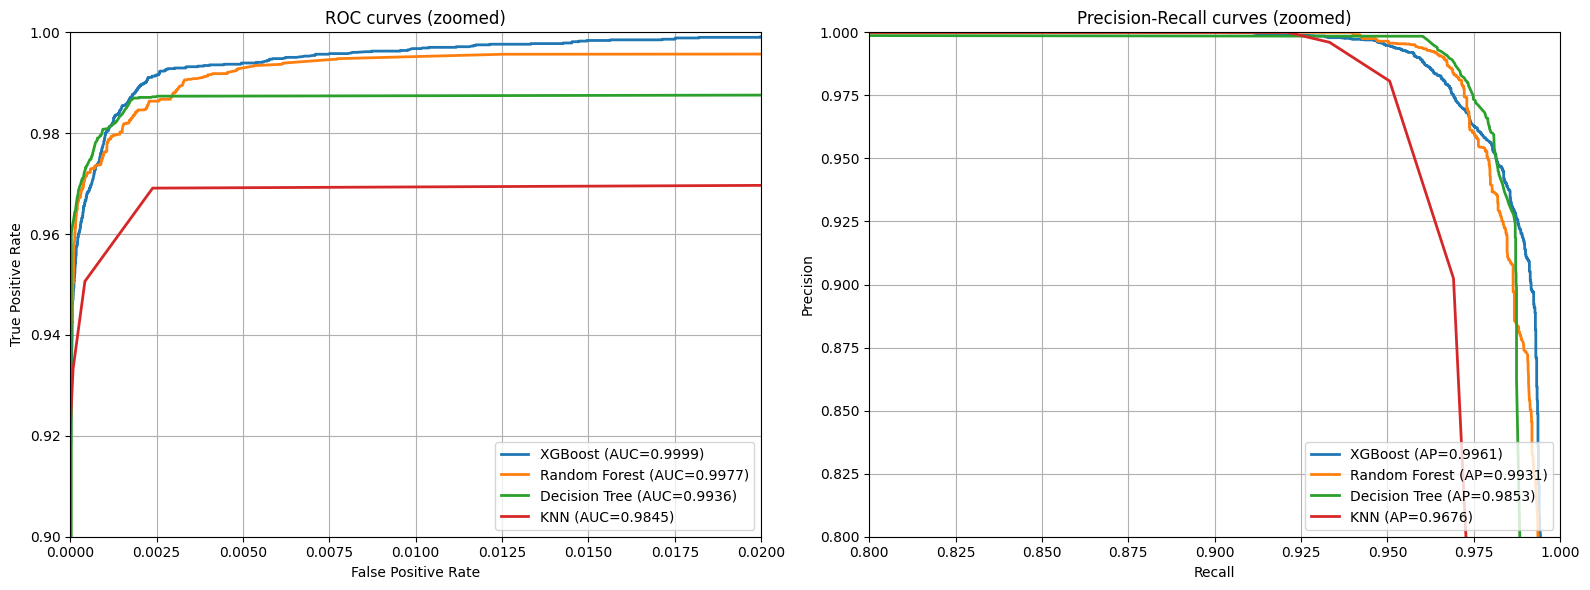

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for name, prob in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC={roc_auc_score(y_test, prob):.4f})")
    p, r, _ = precision_recall_curve(y_test, prob)
    ax[1].plot(r, p, lw=2, label=f"{name} (AP={average_precision_score(y_test, prob):.4f})")

ax[0].set(xlim=(0, 0.02), ylim=(0.90, 1.0), xlabel="False Positive Rate",
          ylabel="True Positive Rate", title="ROC curves")
ax[1].set(xlim=(0.8, 1.0), ylim=(0.8, 1.0), xlabel="Recall",
          ylabel="Precision", title="Precision-Recall curves")
for a in ax:
    a.grid(True); a.legend(loc="lower right")
plt.tight_layout(); plt.show()